# Exploratory Data Analysis

## TRUST-XIDS — Notebook 2

This notebook explores the **cleaned** UNSW-NB15 and CICIDS2017 datasets
(output of Notebook 1), separately, before any feature-selection or
modeling decisions are made.

### Objective

- Dataset statistics for each dataset.
- Attack / label distribution (binary and multiclass).
- Feature distributions for a selected set of important numerical features.
- Correlation analysis among features (not including the target).
- Class imbalance, quantified.

As in Notebook 1: CICIDS2017 currently has 2 of its 8 daily files loaded.
Anything below that reads as "CICIDS2017 is mostly benign with a handful of
brute-force/web attacks" reflects *this run's* 2 days, not the full dataset
— re-running this notebook after Notebook 1 is re-run with all 8 days will
change these numbers, especially the attack-category mix.

# 1. Load Cleaned Data

Using the **unscaled** cleaned files from Notebook 1 — scaling would distort the distributions and correlations we're trying to look at here.

In [1]:
import os

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

BASE_DIR = r"C:\Users\Anu\OneDrive\Desktop\IDS"
PROCESSED_DIR = os.path.join(BASE_DIR, "data/processed")

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
unsw_train = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_train_cleaned.csv"))
unsw_test = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_test_cleaned.csv"))

cic_train = pd.read_csv(os.path.join(PROCESSED_DIR, "cicids_train_cleaned.csv"))
cic_test = pd.read_csv(os.path.join(PROCESSED_DIR, "cicids_test_cleaned.csv"))

print("UNSW train shape  :", unsw_train.shape)
print("CICIDS train shape:", cic_train.shape)

UNSW train shape  : (175341, 44)
CICIDS train shape: (2016638, 80)


# 2. Dataset Statistics

We analyze the **training set** of each dataset throughout this notebook —
the test set is left untouched until model evaluation, consistent with
Notebook 1's leakage safeguards.

In [3]:
print("UNSW-NB15 (train)")
print("Records            :", unsw_train.shape[0])
print("Features           :", unsw_train.shape[1] - 2)  # excluding label, attack_cat_encoded
print("Missing values     :", unsw_train.isnull().sum().sum())
print()
print("CICIDS2017 (train)")
print("Records            :", cic_train.shape[0])
print("Features           :", cic_train.shape[1] - 2)  # excluding label, label_cat_encoded
print("Missing values     :", cic_train.isnull().sum().sum())

UNSW-NB15 (train)
Records            : 175341
Features           : 42
Missing values     : 0

CICIDS2017 (train)
Records            : 2016638
Features           : 78
Missing values     : 0


In [4]:
unsw_train.describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
dur,175341.0,1.359389,6.480249,0.0,0.000008,0.001582,0.668069,5.999999e+01
proto,175341.0,109.606675,22.352601,0.0,113.000000,113.000000,119.000000,1.320000e+02
service,175341.0,1.618920,2.305151,0.0,0.000000,0.000000,2.000000,1.200000e+01
state,175341.0,2.355176,0.867942,0.0,2.000000,2.000000,3.000000,8.000000e+00
spkts,175341.0,20.298664,136.887597,1.0,2.000000,2.000000,12.000000,9.616000e+03
dpkts,175341.0,18.969591,110.258271,0.0,0.000000,2.000000,10.000000,1.097400e+04
sbytes,175341.0,8844.843836,174765.644309,28.0,114.000000,430.000000,1418.000000,1.296523e+07
dbytes,175341.0,14928.918564,143654.217718,0.0,0.000000,164.000000,1102.000000,1.465555e+07
rate,175341.0,95406.187105,165400.978457,0.0,32.786140,3225.806520,125000.000300,1.000000e+06
sttl,175341.0,179.546997,102.940011,0.0,62.000000,254.000000,254.000000,2.550000e+02


In [5]:
cic_train.describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
Destination Port,2016638.0,8.684874e+03,1.900713e+04,0.0,53.0,80.0,4.430000e+02,6.553500e+04
Flow Duration,2016638.0,1.659789e+07,3.523487e+07,-12.0,209.0,50667.0,5.338535e+06,1.200000e+08
Total Fwd Packets,2016638.0,1.057677e+01,8.236431e+02,1.0,2.0,2.0,6.000000e+00,2.197590e+05
Total Backward Packets,2016638.0,1.196931e+01,1.097825e+03,0.0,1.0,2.0,5.000000e+00,2.919220e+05
Total Length of Fwd Packets,2016638.0,6.051642e+02,6.445654e+03,0.0,12.0,66.0,3.320000e+02,2.321478e+06
Total Length of Bwd Packets,2016638.0,1.904944e+04,2.487402e+06,0.0,6.0,156.0,9.970000e+02,6.554530e+08
Fwd Packet Length Max,2016638.0,2.310964e+02,7.548603e+02,0.0,6.0,40.0,2.030000e+02,2.482000e+04
Fwd Packet Length Min,2016638.0,1.921776e+01,6.089702e+01,0.0,0.0,2.0,3.700000e+01,2.325000e+03
Fwd Packet Length Mean,2016638.0,6.343593e+01,1.950489e+02,0.0,6.0,36.3,5.200000e+01,5.940857e+03
Fwd Packet Length Std,2016638.0,7.725991e+01,2.963386e+02,0.0,0.0,0.0,7.424135e+01,7.125597e+03


# 3. Binary Label Distribution (Attack vs Normal)

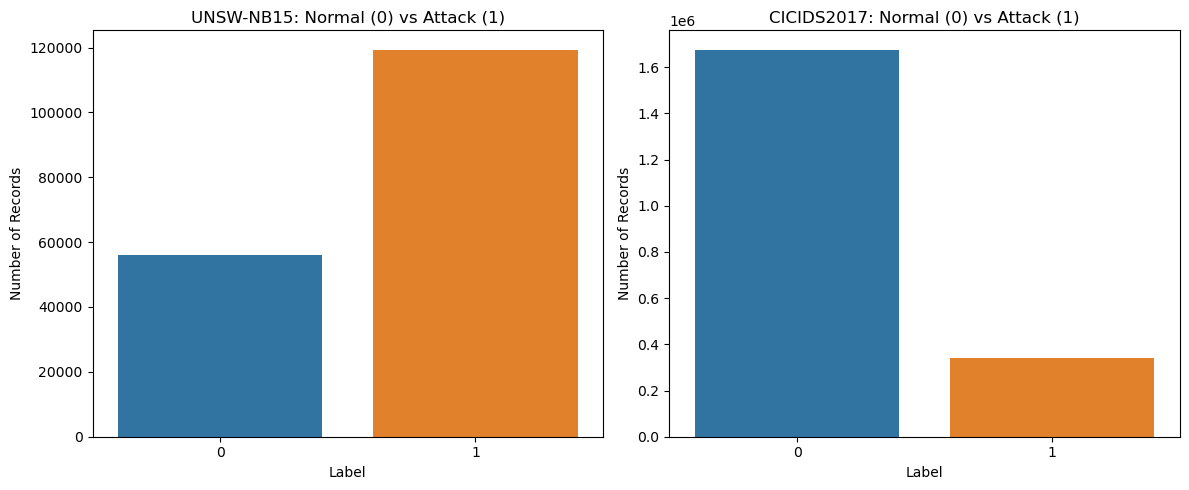

UNSW label counts:
 label
1    119341
0     56000
Name: count, dtype: int64

CICIDS label counts:
 label
0    1676045
1     340593
Name: count, dtype: int64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x="label", data=unsw_train, ax=axes[0])
axes[0].set_title("UNSW-NB15: Normal (0) vs Attack (1)")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Number of Records")

sns.countplot(x="label", data=cic_train, ax=axes[1])
axes[1].set_title("CICIDS2017: Normal (0) vs Attack (1)")
axes[1].set_xlabel("Label")
axes[1].set_ylabel("Number of Records")

plt.tight_layout()
plt.show()

print("UNSW label counts:\n", unsw_train["label"].value_counts())
print()
print("CICIDS label counts:\n", cic_train["label"].value_counts())

# 4. Multiclass Attack Category Distribution

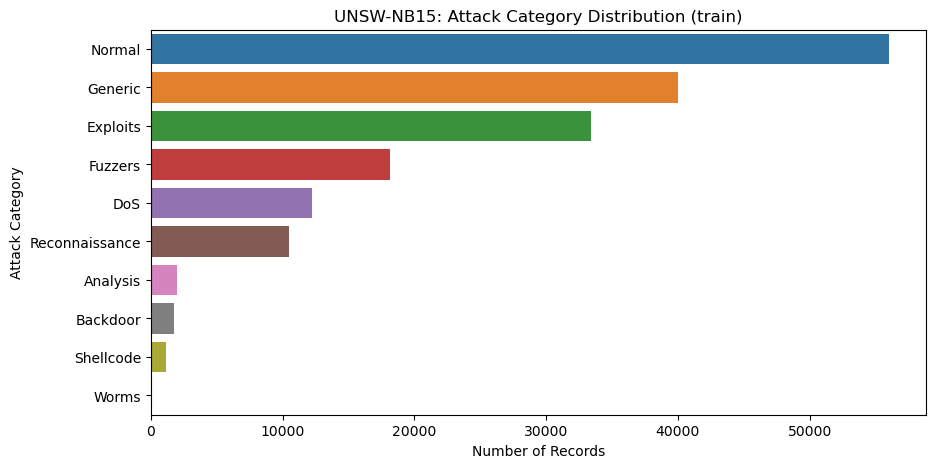

In [7]:
unsw_attack_cat_encoder = __import__("joblib").load(os.path.join(PROCESSED_DIR, "unsw_attack_cat_encoder.joblib"))
unsw_train_cats = unsw_attack_cat_encoder.inverse_transform(unsw_train["attack_cat_encoded"])

plt.figure(figsize=(10, 5))
order = pd.Series(unsw_train_cats).value_counts().index
sns.countplot(y=unsw_train_cats, order=order)
plt.title("UNSW-NB15: Attack Category Distribution (train)")
plt.xlabel("Number of Records")
plt.ylabel("Attack Category")
plt.show()

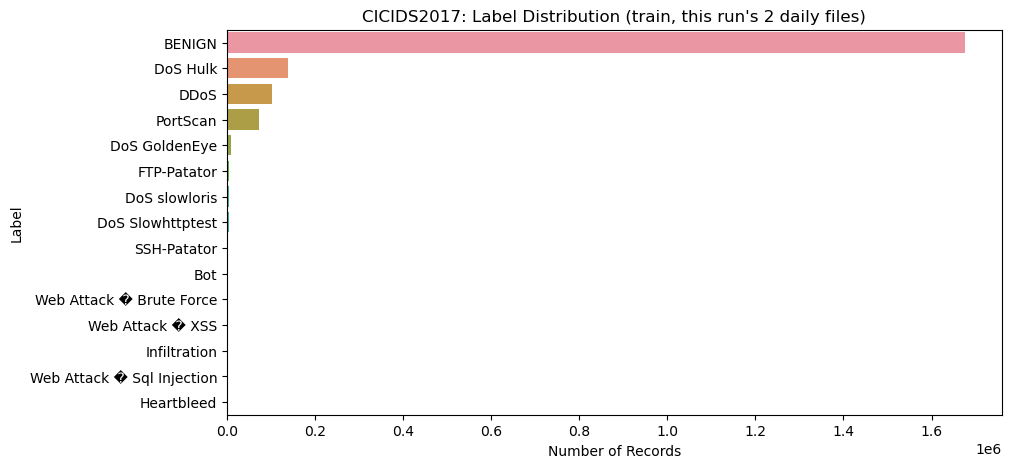

In [8]:
cic_label_encoder = __import__("joblib").load(os.path.join(PROCESSED_DIR, "cic_label_encoder.joblib"))
cic_train_labels = cic_label_encoder.inverse_transform(cic_train["label_cat_encoded"])

plt.figure(figsize=(10, 5))
order = pd.Series(cic_train_labels).value_counts().index
sns.countplot(y=cic_train_labels, order=order)
plt.title("CICIDS2017: Label Distribution (train, this run's 2 daily files)")
plt.xlabel("Number of Records")
plt.ylabel("Label")
plt.show()

**Observation:** UNSW-NB15's attack categories are reasonably spread
across 9 attack types plus Normal, with `Generic` and `Exploits` being the
largest attack categories (this is consistent with the dataset's known
composition). CICIDS2017, in this 2-file run, is dominated by BENIGN
traffic, with FTP-Patator and SSH-Patator (brute-force attacks, from
Tuesday) as the largest attack classes, and the Web Attack subtypes (from
Thursday-Morning) each present in much smaller numbers — `Web Attack - Sql
Injection` is a tiny class (around 20 records), which is worth remembering
when any model's per-class recall is interpreted later: a class this small
can look unstable across splits for reasons unrelated to model quality.

# 5. Feature Distributions

A handful of important numerical features per dataset — not every column, since that produces dozens of plots without analytical value.

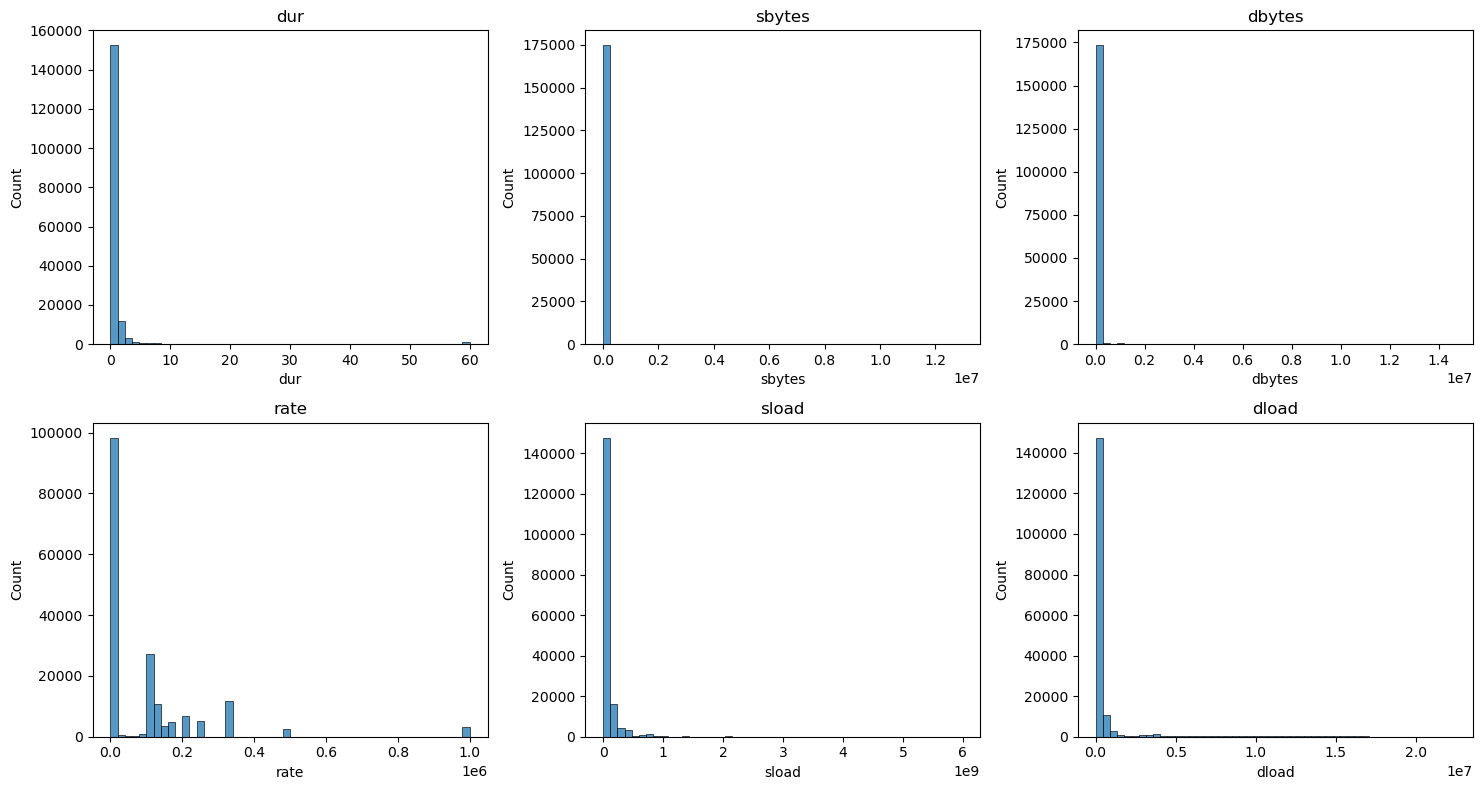

In [9]:
unsw_cols_to_plot = ["dur", "sbytes", "dbytes", "rate", "sload", "dload"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(unsw_cols_to_plot):
    sns.histplot(unsw_train[col], bins=50, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

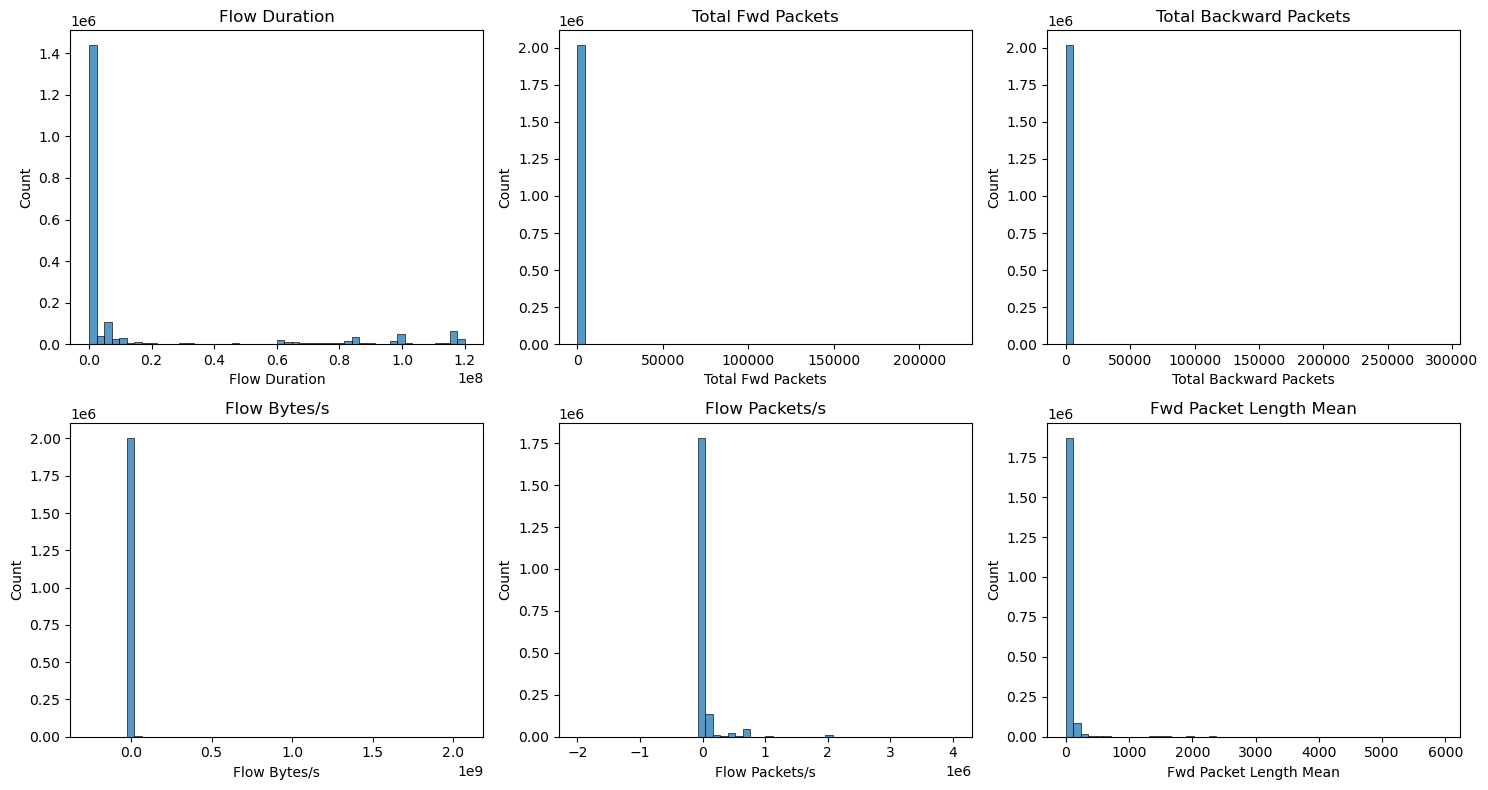

In [10]:
cic_cols_to_plot = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets", "Flow Bytes/s", "Flow Packets/s", "Fwd Packet Length Mean"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(cic_cols_to_plot):
    sns.histplot(cic_train[col], bins=50, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

**Observation:** Both datasets' traffic features are heavily
right-skewed — most flows are short/small, with a long tail of large or
long-duration flows. This is expected for network traffic and is one reason
tree-based models (which split on thresholds rather than assuming any
particular distribution shape) tend to handle this kind of data well without
needing a log-transform, while distance-based models like SVM benefit
strongly from the `StandardScaler` already applied in Notebook 1.

# 6. Correlation Analysis

Feature-to-feature correlation only (not including the label) — this is about finding redundant features, not about label leakage, which is handled separately in Notebook 3.

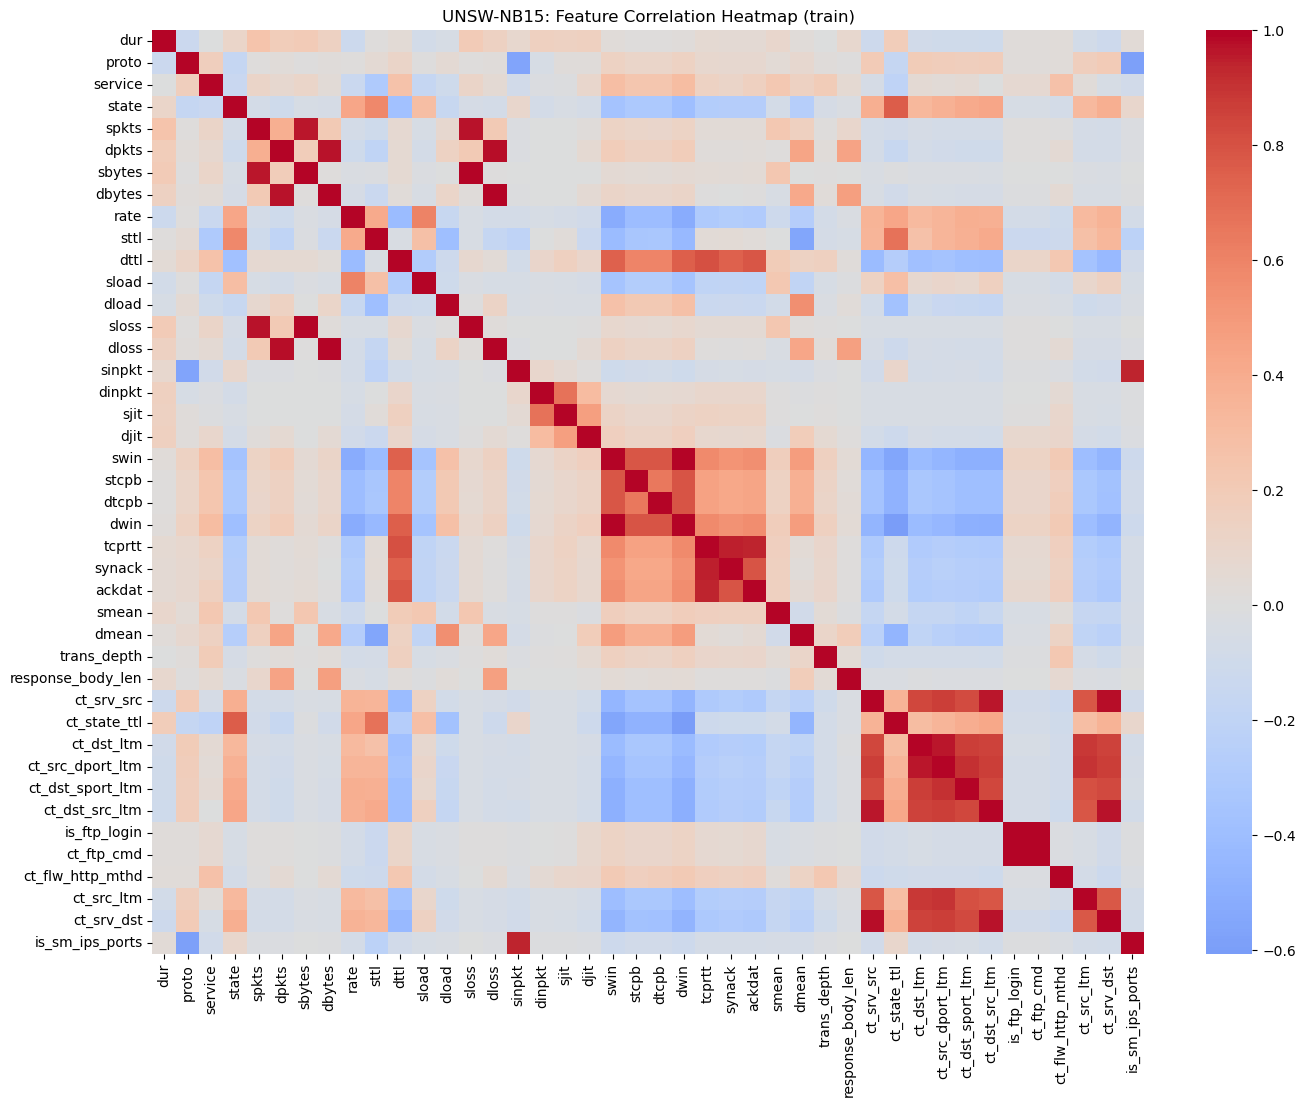

In [11]:
unsw_numeric = unsw_train.drop(columns=["label", "attack_cat_encoded"]).select_dtypes(include=[np.number])

plt.figure(figsize=(16, 12))
sns.heatmap(unsw_numeric.corr(), cmap="coolwarm", center=0)
plt.title("UNSW-NB15: Feature Correlation Heatmap (train)")
plt.show()

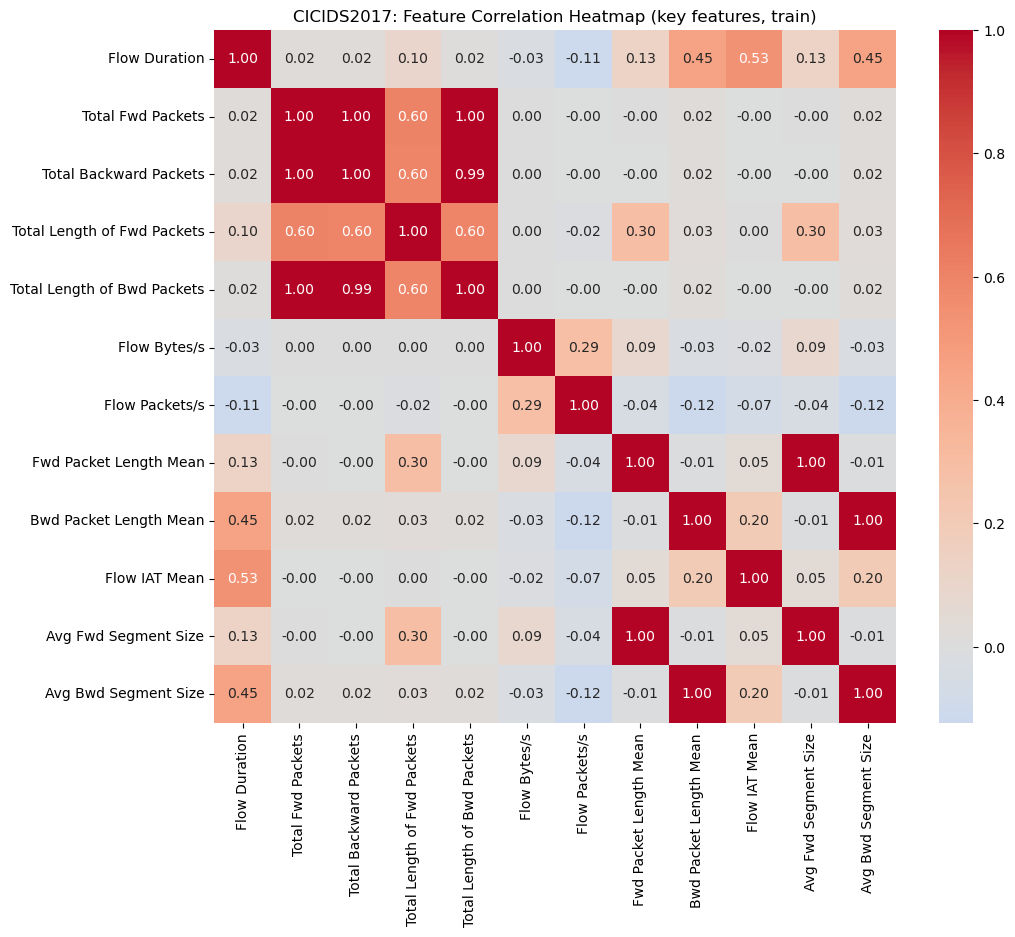

In [12]:
cic_corr_cols = [
    "Flow Duration", "Total Fwd Packets", "Total Backward Packets",
    "Total Length of Fwd Packets", "Total Length of Bwd Packets",
    "Flow Bytes/s", "Flow Packets/s", "Fwd Packet Length Mean",
    "Bwd Packet Length Mean", "Flow IAT Mean", "Avg Fwd Segment Size", "Avg Bwd Segment Size"
]

plt.figure(figsize=(11, 9))
sns.heatmap(cic_train[cic_corr_cols].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("CICIDS2017: Feature Correlation Heatmap (key features, train)")
plt.show()

**Observation:** Several UNSW-NB15 feature pairs (e.g. the various
`ct_*` connection-count features, and `sbytes`/`smean`) are highly
correlated, as expected since they're derived from the same underlying
connection statistics. `Fwd Packet Length Mean` and `Avg Fwd Segment Size`
in CICIDS2017 show very high correlation — unsurprising since CICFlowMeter
documentation defines them almost identically. High correlation here flags
candidates for redundancy reduction in Notebook 3, but is not by itself a
reason to drop a feature: low correlation with other features doesn't mean
a feature is uninformative for the target, and that's checked separately
with feature importance in Notebook 3.

# 7. Class Imbalance

In [13]:
unsw_imbalance_ratio = unsw_train["label"].value_counts(normalize=True)
cic_imbalance_ratio = cic_train["label"].value_counts(normalize=True)

print("UNSW-NB15 class proportions (train):")
print(unsw_imbalance_ratio)
print()
print("CICIDS2017 class proportions (train, this run):")
print(cic_imbalance_ratio)

imbalance_summary = pd.DataFrame({
    "UNSW-NB15": unsw_imbalance_ratio,
    "CICIDS2017": cic_imbalance_ratio
})
imbalance_summary.index = ["Normal", "Attack"]
imbalance_summary

UNSW-NB15 class proportions (train):
label
1    0.680622
0    0.319378
Name: proportion, dtype: float64

CICIDS2017 class proportions (train, this run):
label
0    0.831109
1    0.168891
Name: proportion, dtype: float64


,UNSW-NB15,CICIDS2017
Normal,0.319378,0.831109
Attack,0.680622,0.168891


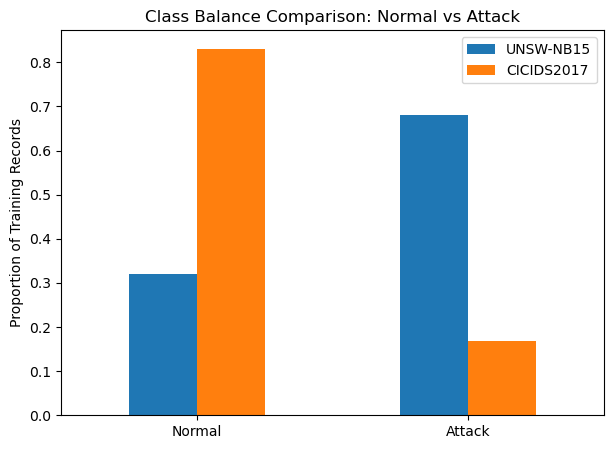

In [14]:
imbalance_summary.plot(kind="bar", figsize=(7, 5))
plt.title("Class Balance Comparison: Normal vs Attack")
plt.ylabel("Proportion of Training Records")
plt.xticks(rotation=0)
plt.show()

**Observation:** UNSW-NB15 is skewed toward **Attack** (roughly 68%
attack / 32% normal in the official training split) — an unusual direction
for an intrusion-detection dataset, but a known property of UNSW-NB15's
official split. CICIDS2017, in this 2-file run, is skewed heavily toward
**Normal** (over 98% benign), which is the more typical pattern for network
traffic and will likely moderate somewhat (more attack traffic, less
extreme skew) once the DDoS/PortScan/DoS-heavy days are added. Neither
imbalance is resampled here — any oversampling/undersampling, if used later
in Notebook 4, will be applied to the training fold only, never to the
combined or test data.

# 8. Summary

- **UNSW-NB15** (train): 175,341 records, 42 features, 0 missing values.
  Skewed toward **Attack** (68.1% attack / 31.9% normal) — unusual for an
  IDS dataset, but a known property of UNSW-NB15's official split. 9 attack
  categories present (`Generic` and `Exploits` the largest).
- **CICIDS2017** (train, 2 of 8 daily files): 465,528 records, 78 features,
  0 missing values after Notebook 1's cleaning. Skewed toward **Normal**
  (98.1% benign / 1.9% attack) — the more typical direction for network
  traffic, and this is before the DDoS/PortScan/DoS-heavy days are added,
  which will raise the attack proportion substantially.
- Both datasets' numerical features are heavily right-skewed (most flows
  short/small, long tail of large ones) — consistent with real network
  traffic and a reason tree-based models tend to do well here without
  needing a log-transform.
- Correlation heatmaps surfaced redundant feature groups in both datasets
  (UNSW's `ct_*` connection-count features; CICIDS's `Fwd Packet Length
  Mean` vs `Avg Fwd Segment Size`) — candidates for review in Notebook 3,
  not automatic removals.
- Class imbalance is present in both datasets, in opposite directions —
  any resampling used later must be fit on the training fold only.

**Next (Notebook 3 — Feature Selection):** use these correlation and
distribution observations, plus feature-importance rankings, to decide on
a reduced/redundancy-checked feature set, and build the harmonized
cross-dataset feature mapping.